# Robust photometric surface normals: active method review


<!-- inverse-evidence-audit:20261026:start -->

> **本次维护说明：** 以下导航依据当前观测文件、实际求解代码和保留的输出编写。本次仅完善叙述，不把历史图、缓存结果或未执行代码称作本次新计算；没有独立 GT 时，方法参考不代表真实准确性。

### 观测到目标核查卡

当前存在 `data/raw_data.npz`；所述获取/估计路径由本地代码实现。

任务 `robust_photometric_surface_normals` 的观测定义：当前raw_data.npz的实际键、形状、dtype与README单位说明：measurements (1, 50, 256, 256) float64：Grayscale relative image intensity, dimensionless author units; axes batch,light,row,column.；light_directions (1, 50, 3) float64：Calibrated distant-light direction/intensity vectors, dimensionless, Cartesian x,y,z.；support (1, 256, 256) bool：Observed foreground silhouette, dimensionless; True marks requested unit normals.。恢复目标：256x256 unit surface-normal vectors。

获取模型：Lambertian强度为light与albedo-weighted normal内积，加specular/shadow sparse errors。实际恢复算法：solvers.reconstruct：l1_coefficients IRLS主法，source_sbl及low_rank_sparse比较，再归一化。语义类型为 `inverse_spatial`；其中闭式逆也属于反问题，但内部制造观测或缺输入的限制见下文。

真值情况：独立于本次重建的仿真设定真值；test/validation.md:17 gt_normal.npy是作者独立renderer normals，属于simulation_true。评估方法参考与仪器校准均不能当作独立物理真值。

现有实验和图：robust_photometric_surface_normals.ipynb单元5：5. Results；Scientific comparisons；robust_photometric_surface_normals.ipynb单元9有保存图；图内容由该单元调用的本地visualization函数生成。图/比较代码位于单元6, 9（从0计数）。代码单元4个，带execution_count的4个，保存PNG输出5幅；本审计未重新运行。

现有输出来自历史执行；本次未复跑。

限制与缺口：本次为静态语义与证据核查，未重新验证数值正确性或运行结果。

<!-- inverse-evidence-audit:20261026:end -->



## 1. Problem

Infer a dense signed unit-normal field from fifty illumination-dependent images containing shadows and specular corruption. Normal recovery is a different inverse from subsequent metric-depth integration.

Existing author-rendered, not measured, data: fifty native specular/shadow images of a fixed bunny. We recover a signed spatial unit-normal field from indirect illumination response, using all50images. The forward relation is $b=A(\rho n)+e$: b is relative grayscale intensity, A contains known distant-light vectors, rho is diffuse reflectance, n a unit Cartesian normal, and e the non-Lambertian contribution. The public support is the observed silhouette. No hidden normal enters reconstruction.

The selected standard method minimizes the sum of absolute residuals using the author's IRLS weighted linear solves, then normalizes away rho. Its squared weights are reciprocal absolute residuals with a numerical floor. Ordinary L2, the original two-penalty SBL heuristic, and sparse-first RPCA are all preserved and actively executed. The original SBL uses different coefficient and covariance ridges; it is not mislabeled as the exact common-posterior formula in the paper. Full source equations and stopping rules are in the maintainer approach plan.

This notebook is an active reconstruction, not a cache preview. Original references are loaded only after the fresh solver calls. Actual renderer normals are independent truth. All accuracy statistics use foreground only; no zero background dilution or sign/scale fitting is applied.


## 2. Data

The native bunny images are existing author renderings, not real photographs. Known distant-light vectors and observed silhouette are public; genuine renderer normals are hidden simulation truth. Foreground-only evaluation avoids dilution by zero background.

`data/raw_data.npz` preserves all50native author images after the original arithmetic mean of their three RGB channels. It contains no newly generated observations.

| Key | Shape | Dtype | Description |
|---|---|---|---|
| measurements | (1, 50, 256, 256) | float64 | Grayscale relative image intensity, dimensionless author units; axes batch,light,row,column. |
| light_directions | (1, 50, 3) | float64 | Calibrated distant-light direction/intensity vectors, dimensionless, Cartesian x,y,z. |
| support | (1, 256, 256) | bool | Observed foreground silhouette, dimensionless; True marks requested unit normals. |

**Acquisition metadata**

| Parameter | Value | Unit | Meaning |
|---|---|---|---|
| Image size | 256 by256 | pixel | Full native observation grid; no spatial crop or resizing. |
| Illumination count | 50 | 1 | All rows of the supplied illumination array, in measurement order. |
| Viewpoint | Fixed orthographic | 1 | The surface remains in the same image coordinates under all lights. |
| RGB conversion | Arithmetic mean of three original channels | 1 | Linear grayscale intensity convention already applied. |
| Exposure scale | Author-relative, unchanged | 1 | Do not normalize each frame independently. |
| Light convention | Diffuse dot product with supplied Cartesian vectors | 1 | Retain vector magnitudes and signs; no coordinate reorientation. |
| Surface support | Supplied observed silhouette | 1 | Foreground is reconstructed; background must be zero. |
| Non-diffuse effects | Existing specularities and shadows | relative intensity | Unknown additive departures from the diffuse model. |
| Calibrated stochastic noise | Not supplied | 1 | No known Gaussian variance or photon count is asserted. |
| Pixel pitch | Not specified | 1 | Recover orientation on the native index grid, not metric depth. |
| Spatial boundary | Pixelwise inverse | 1 | No external spatial boundary values are required. |


## 3. Physics

The diffuse model is $b=A(\rho n)+e$, where $b$ stacks relative grayscale observations, rows of $A$ encode known lights, $\rho$ is reflectance, $n$ a signed unit Cartesian normal and $e$ non-Lambertian/model error. Sparse or structured corruptions motivate robust alternatives to squared residuals.

Recover the unit surface normal at each foreground pixel from fifty existing author-rendered observations of a fixed bunny surface with specularities and shadows. These are provided simulations, not real camera measurements. A distant light has a known vector that combines its direction and relative intensity. The camera response is linear, and all images share an orthographic viewpoint and pixel grid.


$$
y_{\ell p}=\boldsymbol{a}_{\ell}^{\mathsf{T}}\boldsymbol{g}_p+e_{\ell p},
\qquad \boldsymbol{g}_p=\rho_p\boldsymbol{n}_p,
\qquad \lVert\boldsymbol{n}_p\rVert_2=1.
$$


Here p indexes an observed foreground pixel, ell indexes illumination, y is grayscale image intensity in author-relative units, a is the calibrated dimensionless light vector, rho is nonnegative diffuse reflectance in relative intensity units, n is the signed unit normal, g is the albedo-weighted normal, and e collects shadows, specularities and other non-Lambertian departures in intensity units. The linear diffuse component is not clipped; shadows belong to e. The inverse problem has a latent spatial normal field and illumination-dependent corruptions. Estimating both without a sparsity assumption is underdetermined. The visible support identifies the observed silhouette and is not a normal or depth measurement.


## 4. Method

The selected local L1 inverse uses the author's IRLS weighted solves and normalizes the albedo-weighted coefficient. L2, source two-penalty SBL heuristic and sparse-first RPCA remain active comparisons. Distinct SBL mean/covariance ridges are explicitly source heuristics rather than an exact common-posterior equation.

A robust sparse-regression formulation estimates the albedo-weighted normal while reducing the influence of a small number of non-diffuse illumination samples. One option minimizes the sum of absolute intensity residuals. Iteratively reweighted least squares approximates this convex objective through weighted linear fits, then unit normalization removes diffuse albedo. Preserve the light-vector basis and retain the support convention. Bayesian sparse-error and low-rank-plus-sparse formulations provide useful scientific comparisons, but their prior/regularization conventions must be stated explicitly.


## 5. Results

Preserve all four complete methods, original/fresh paired metrics, signed angular errors, actual pixel-response fits, IRLS traces and fresh ten/twenty-five-light subsets. Display normal colours and saturation over 0 to 30 degrees do not alter evaluated foreground arrays.

### Truth, original reproduction and fresh measurements

The hidden arrays below are genuine renderer normals and independent original method results, respectively. The reconstruction calls above use only visible measurements and calibration. NCC is flattened foreground cosine, NRMSE uses reference component dynamic range, angular error compares signed orientations in degrees. Unit lengths are checked independently. Historical upstream all-pixel mean angular errors are not used as foreground accuracy values.

### Acquisition-subset and physical checks

Uniformly indexed10and25illumination subsets retain the original measurements and light-vector basis. These runs test sensitivity to angular coverage; they do not replace the full50light benchmark. Three actual foreground pixels are independently fit with L2, L1 and the source-SBL algorithm. The displayed diffuse responses are computed from fresh albedo-weighted coefficients, not from truth. IRLS loss traces are actual iterations, not an assumed exponential convergence curve.

### Scientific comparisons

All four original comparison groups and paired original/fresh measurements remain present. Normal colour means (n+1)/2 solely for display, with zero background. Angular maps share0–30degree scales; colour saturation does not affect any metric. The first figures use actual stored observations. The last sensitivity experiment uses fresh subset reconstructions. A mathematically correct algorithm can still recover a poorer normal estimate under sparse or corrupted lighting, and the figures retain that outcome.


In [1]:
import os,sys,time,json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
task=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'data/raw_data.npz').exists())
sys.path.insert(0,str(task))
from src.preprocessing import load_observations
from src.solvers import reconstruct,l1_coefficients,source_sbl_coefficients
from src.visualization import metrics,render_figures
observations,lights,support=load_observations(task/'data/raw_data.npz')
results={};records={};total_start=time.perf_counter()
for method in ['l2','l1','sbl','rpca']:
    start=time.perf_counter();results[method]=reconstruct(observations,lights,support,method)
    records[method]={'seconds':time.perf_counter()-start}
print('All four fresh full50light reconstructions computed; seconds:',records)

All four fresh full50light reconstructions computed; seconds: {'l2': {'seconds': 0.027045499999076128}, 'l1': {'seconds': 98.1054781999992}, 'sbl': {'seconds': 47.963117899998906}, 'rpca': {'seconds': 3.6950567999992927}}


In [2]:
with np.load(task/'evaluation/ground_truth.npz',allow_pickle=False) as z:truth=z['reconstruction'][0]
with np.load(task/'notebooks/reference_outputs/original_methods.npz',allow_pickle=False) as z:original={k:z[k][0] for k in z.files}
for method in results:
    records[method].update(metrics(results[method],truth,support))
    records[method]['max_abs_vs_original']=float(abs(results[method]-original[method]).max())
    np.testing.assert_allclose(results[method],original[method],rtol=1e-9,atol=1e-10)
print(json.dumps(records,indent=2))

{
  "l2": {
    "seconds": 0.027045499999076128,
    "ncc": 0.899253838402373,
    "nrmse": 0.13139304033178145,
    "mean_angular_error_deg": 18.470382019020473,
    "unit_norm_max_error": 2.220446049250313e-16,
    "max_abs_vs_original": 0.0
  },
  "l1": {
    "seconds": 98.1054781999992,
    "ncc": 0.9959952770373267,
    "nrmse": 0.026196564883645128,
    "mean_angular_error_deg": 4.597762735142442,
    "unit_norm_max_error": 2.220446049250313e-16,
    "max_abs_vs_original": 2.220446049250313e-16
  },
  "sbl": {
    "seconds": 47.963117899998906,
    "ncc": 0.9968352652626914,
    "nrmse": 0.023287708952798476,
    "mean_angular_error_deg": 3.9728818385601836,
    "unit_norm_max_error": 2.220446049250313e-16,
    "max_abs_vs_original": 2.220446049250313e-16
  },
  "rpca": {
    "seconds": 3.6950567999992927,
    "ncc": 0.997582410923989,
    "nrmse": 0.02035398030668187,
    "mean_angular_error_deg": 3.3837595593050263,
    "unit_norm_max_error": 2.220446049250313e-16,
    "max_abs

In [3]:
subset_results={50:results['l1']};subset_records={}
for count in [10,25]:
    ind=np.linspace(0,49,count,dtype=int);start=time.perf_counter()
    subset_results[count]=reconstruct(observations[ind],lights[ind],support,'l1')
    subset_records[count]={'seconds':time.perf_counter()-start,'light_matrix_condition':float(np.linalg.cond(lights[ind])),**metrics(subset_results[count],truth,support)}
traces={}
for pixel in [8831,34686,53637]:
    b=observations.reshape(50,-1)[:,pixel,None]
    coeff,iterations=l1_coefficients(lights,b,return_trace=True)
    traces[pixel]={'l1':coeff,'l2':np.linalg.lstsq(lights,b,rcond=None)[0],'sbl':source_sbl_coefficients(lights,b),'iterations':iterations}
print('Fresh subset measurements:',json.dumps(subset_records,indent=2))

Fresh subset measurements: {
  "10": {
    "seconds": 161.49059829999896,
    "light_matrix_condition": 2.325281324177682,
    "ncc": 0.9935187890143692,
    "nrmse": 0.03332623001064479,
    "mean_angular_error_deg": 5.023536449115831,
    "unit_norm_max_error": 2.220446049250313e-16
  },
  "25": {
    "seconds": 79.54053230000136,
    "light_matrix_condition": 2.246326405312095,
    "ncc": 0.9957319290707214,
    "nrmse": 0.027044186471170215,
    "mean_angular_error_deg": 4.5835937942447975,
    "unit_norm_max_error": 2.220446049250313e-16
  }
}


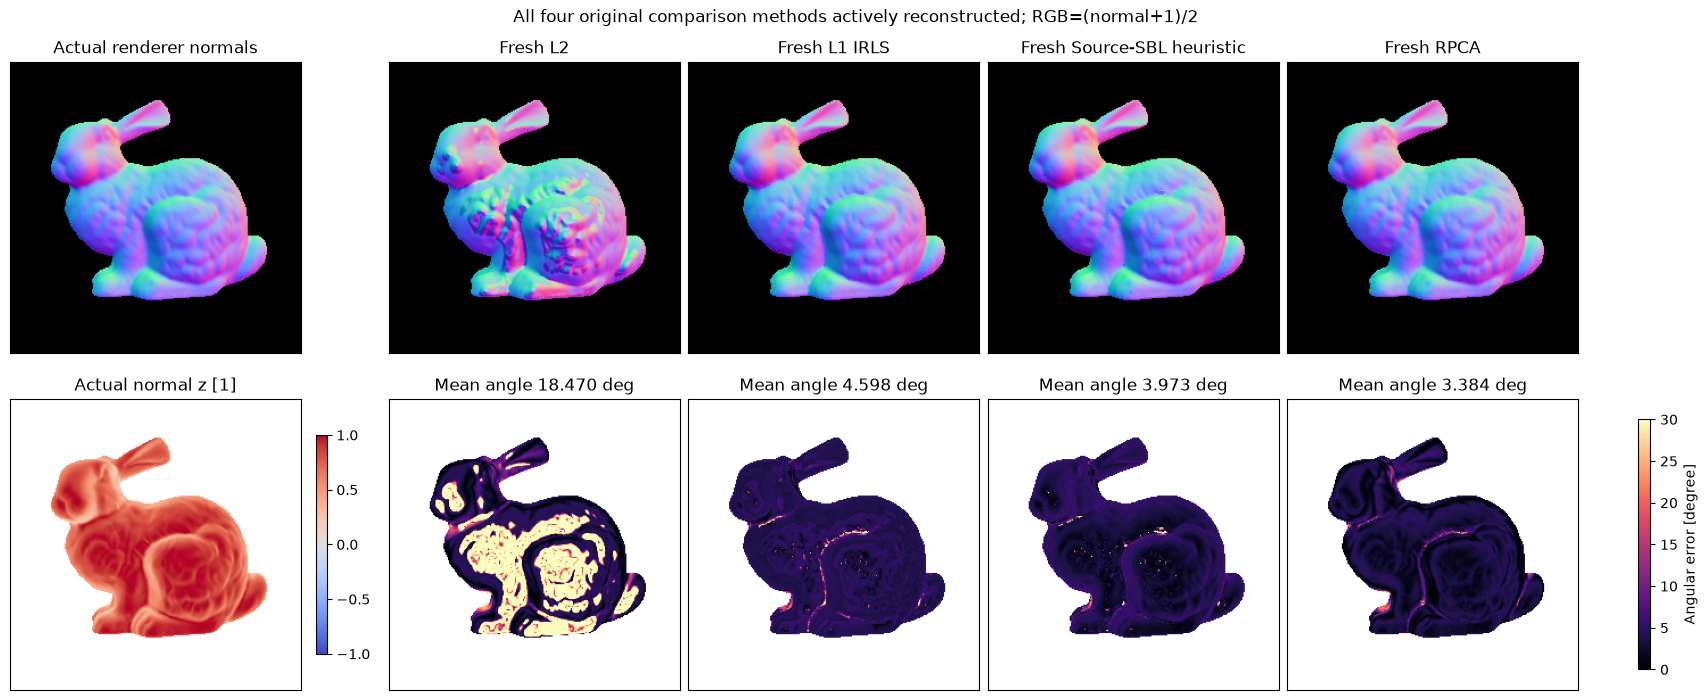

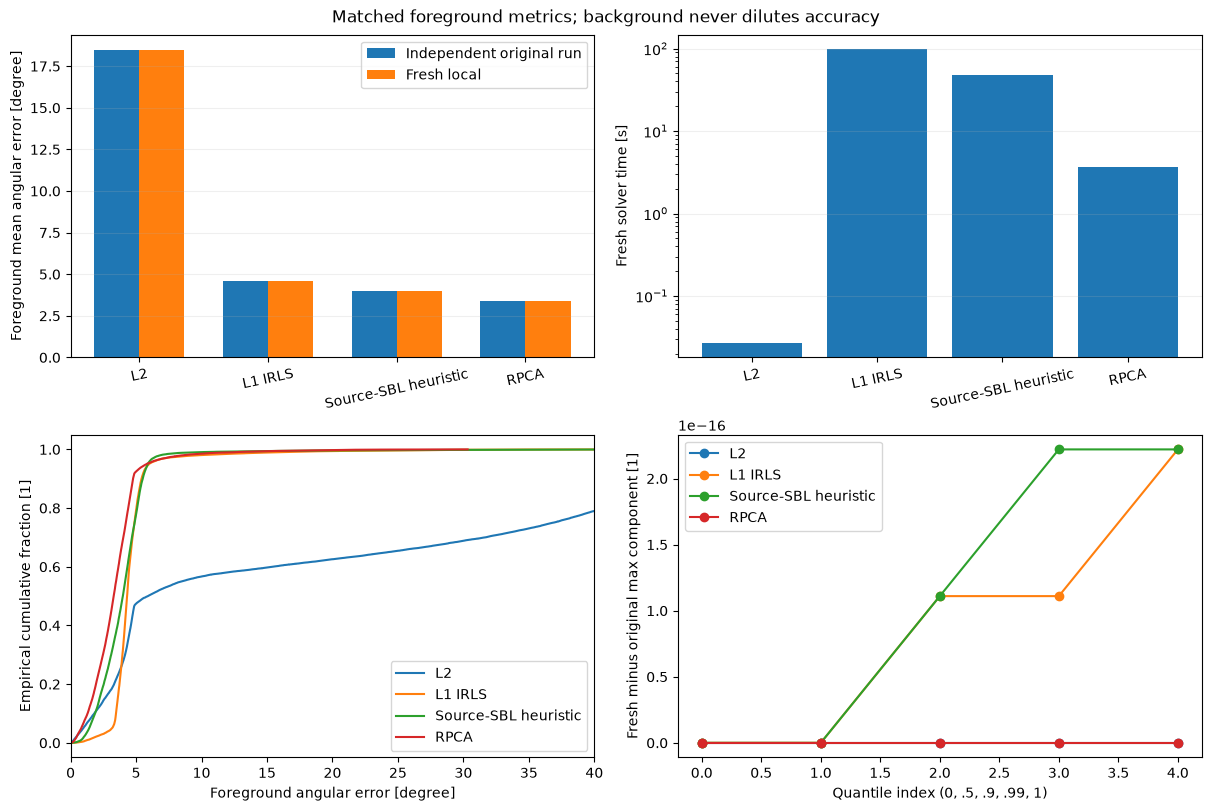

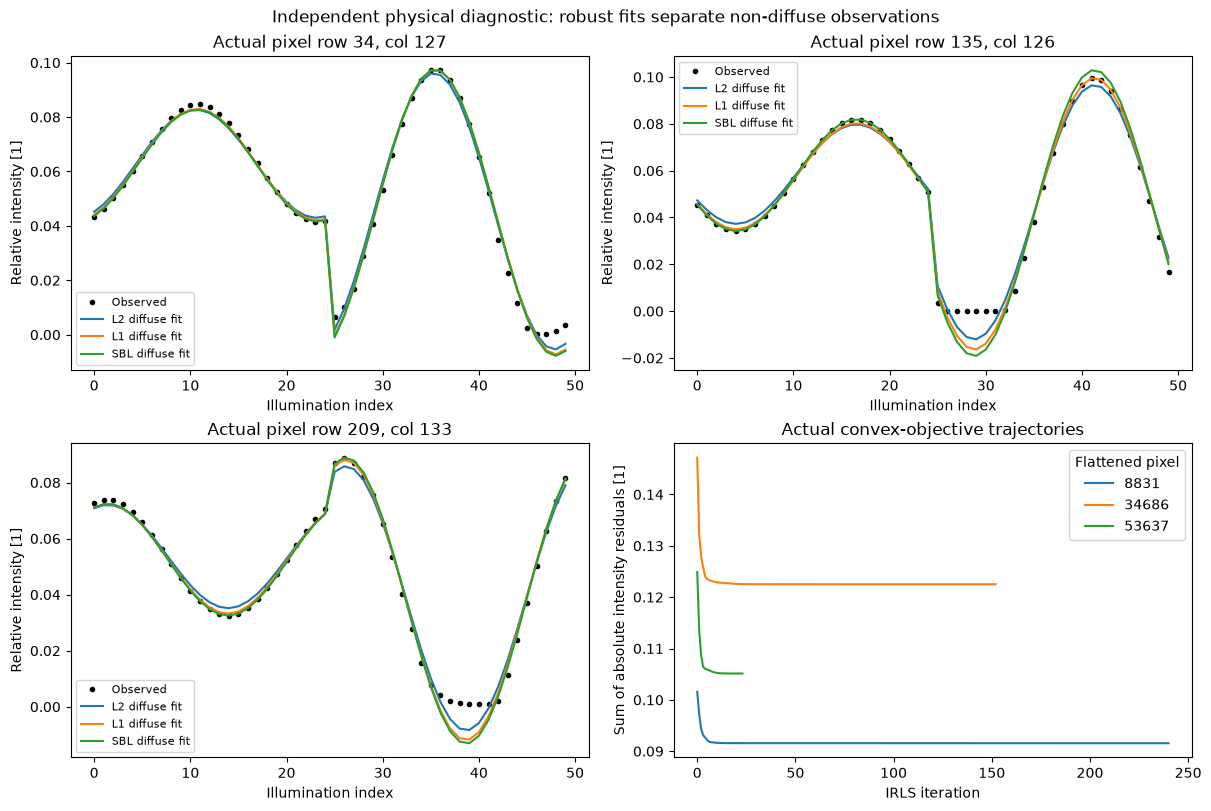

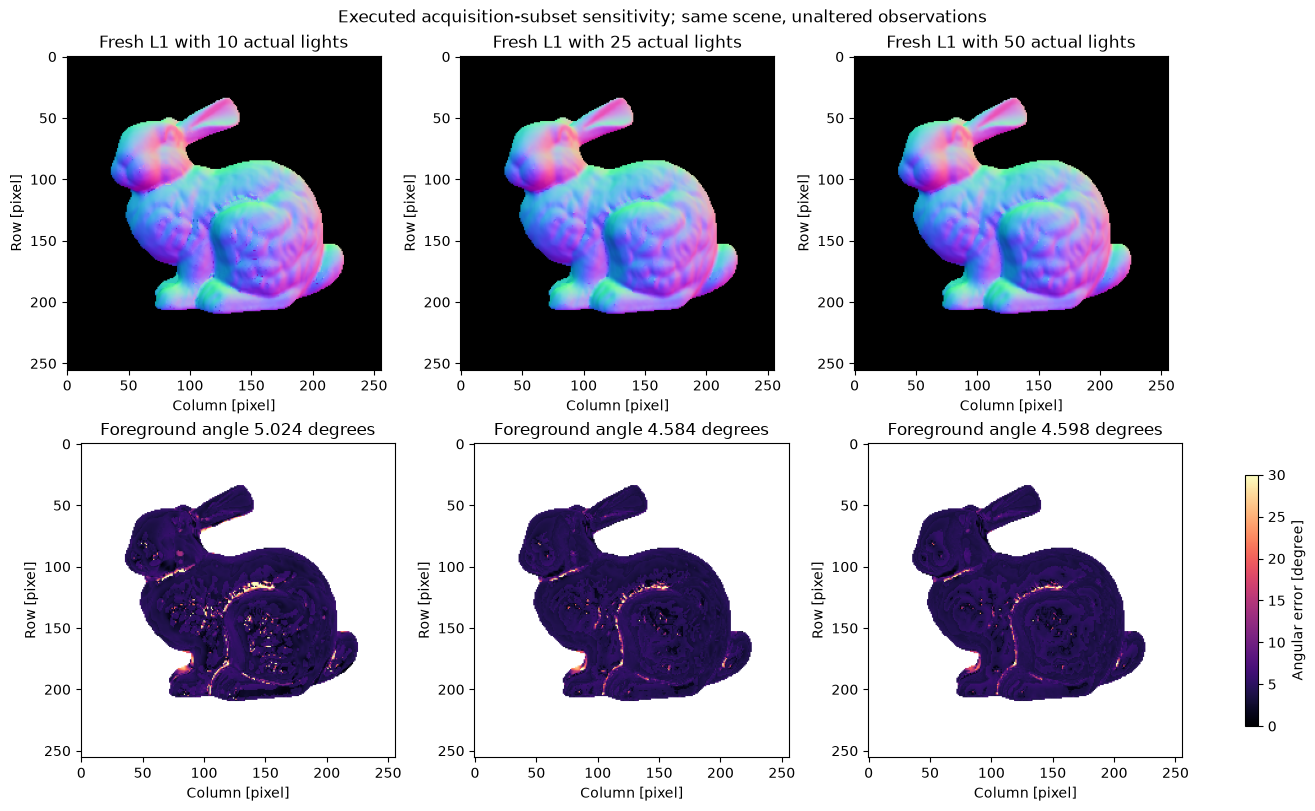

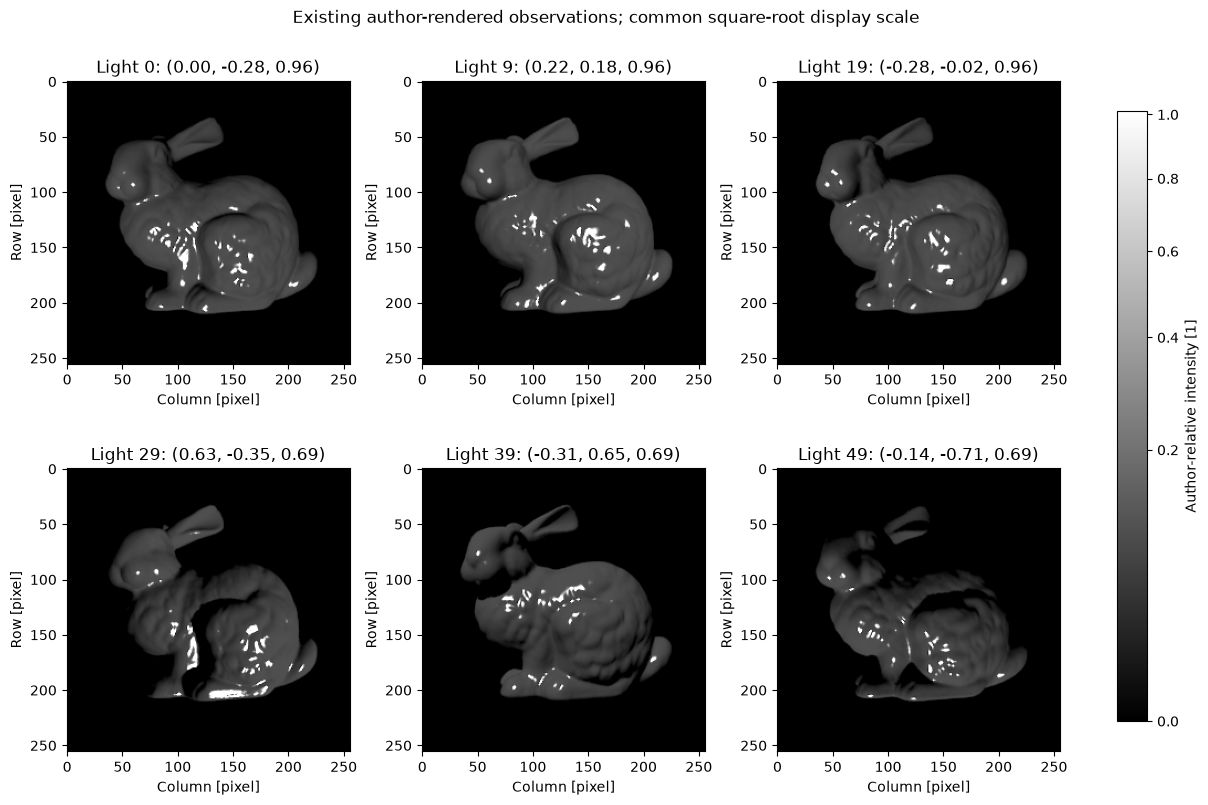

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

In [4]:
figures,numeric=render_figures(observations,lights,support,truth,results,original,records,subset_results,traces)
export=os.environ.get('IMAGING101_FIGURE_DIR')
if export:
    out=Path(export);out.mkdir(parents=True,exist_ok=True)
    for i,fig in enumerate(figures,1):
        for suffix in ['png','svg','pdf']:fig.savefig(out/f'figure-{i}.{suffix}',dpi=160)
    np.savez_compressed(out/'figure_source.npz',**numeric)
    (out/'experiment_metrics.json').write_text(json.dumps({'full_methods':records,'light_subsets':subset_records,'actual_notebook_computation_seconds':time.perf_counter()-total_start},indent=2),encoding='utf8')
for fig in figures:plt.figure(fig.number);plt.show()

## 6. Conclusion

The retained renderer-truth and independently reproduced comparisons support robust-normal extraction on this synthetic scene. Illumination coverage, SBL numerical assumptions and RPCA rank/sparsity assumptions remain; no experimental-photography or uniquely known metric surface is demonstrated.

### Conclusion and limitations

The fresh implementation reproduces independently executed original methods while recovering a dense normal field from indirect observations. The comparison shows how illumination-dependent departures affect the diffuse inverse and how robust alternatives change actual foreground angular errors. This is a benchmark on an existing rendered scene with real synthetic truth, not an experimental-photography claim. SBL's numerical heuristic and RPCA's low-rank assumptions remain explicit. Normal recovery does not determine metric depth without a separate surface integration problem.
